In [2]:
!nvidia-smi    # should show a GPU (e.g. Tesla T4). If error: GPU is not enabled.
from google.colab import drive
drive.mount('/content/drive')

Sat Oct 17 14:37:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [52]:
import os, random, time, copy, glob, shutil
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
from torchvision import transforms, models
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = '/content/drive/MyDrive/glaucoma'
RAW  = f'{ROOT}/raw'
DATA = f'{ROOT}/data'
OUT  = f'{ROOT}/results'
os.makedirs(DATA, exist_ok=True); os.makedirs(OUT, exist_ok=True)
IMG, BATCH, EPOCHS, LR, SEED = 224, 32, 15, 1e-4, 42   # SAME for every model (fair comparison)
# SEED is 42 for the first run; later set SEED = 7, then SEED = 123 and re-run the Day 4 cell
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = (DEVICE == 'cuda')                            # mixed precision = faster training
print('Using device:', DEVICE)
def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

Using device: cuda


In [53]:
IMG_EXT = ('.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp')
def sort_by_rule(src_folder, dataset_name, is_glaucoma):
    '''Copy every image from src_folder into data/dataset_name/{glaucoma|normal}.
    is_glaucoma is a function: file name -> True/False.'''
    n = 0
    for f in os.listdir(src_folder):
        if not f.lower().endswith(IMG_EXT): continue
        cls = 'glaucoma' if is_glaucoma(f) else 'normal'
        dst = f'{DATA}/{dataset_name}/{cls}'
        os.makedirs(dst, exist_ok=True)
        shutil.copy(f'{src_folder}/{f}', f'{dst}/{f}')
        n += 1
    print(dataset_name, 'copied', n, 'images')

In [58]:
rows = []
for ds in sorted(os.listdir(DATA)):
    for cls, label in [('normal', 0), ('glaucoma', 1)]:
        folder = f'{DATA}/{ds}/{cls}'
        if not os.path.isdir(folder): continue
        for f in os.listdir(folder):
            if f.lower().endswith(IMG_EXT):
                rows.append(dict(path=f'{folder}/{f}', label=label, dataset=ds))
df = pd.DataFrame(rows)
df.to_csv(f'{ROOT}/master.csv', index=False)
print(df.groupby(['dataset', 'label']).size().unstack())

label         0    1
dataset             
ACRIMA      309  396
G1020       724  296
ORIGA       482  168
RIM-ONE_DL  313  172


In [57]:
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])   # ImageNet statistics
train_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)), transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15), transforms.ColorJitter(0.2, 0.2),
    transforms.ToTensor(), norm])
eval_tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(), norm])
class FundusDS(Dataset):
    def __init__(self, frame, tf):
        self.paths = frame.path.tolist()
        self.labels = frame.label.values.astype('float32')
        self.tf = tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        return self.tf(img), torch.tensor(self.labels[i])

In [59]:
def split_source(d, seed):
    trval, te = train_test_split(d, test_size=0.15, stratify=d.label, random_state=seed)
    tr, va = train_test_split(trval, test_size=0.15 / 0.85, stratify=trval.label, random_state=seed)
    return tr, va, te
# quick check
d = df[df.dataset == df.dataset.unique()[0]]
tr, va, te = split_source(d, SEED)
print(len(tr), len(va), len(te), '| glaucoma ratio:',
      tr.label.mean().round(2), va.label.mean().round(2), te.label.mean().round(2))

493 106 106 | glaucoma ratio: 0.56 0.56 0.57


In [60]:
def make_model(name):
    if name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Linear(m.fc.in_features, 1)
    elif name == 'densenet121':
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        m.classifier = nn.Linear(m.classifier.in_features, 1)
    elif name == 'mobilenet_v2':
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 1)
    elif name == 'efficientnet_b0':
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 1)
    elif name == 'inception_v3':
        m = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1)
        m.aux_logits = False; m.AuxLogits = None   # turn off the auxiliary head (simplifies training)
        m.fc = nn.Linear(m.fc.in_features, 1)
    else:
        raise ValueError(name)
    return m.to(DEVICE)
print(sum(p.numel() for p in make_model('mobilenet_v2').parameters()) / 1e6, 'million parameters')

2.225153 million parameters


In [61]:
def predict(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                out = model(x)
            ps.append(torch.sigmoid(out.float()).squeeze(1).cpu().numpy())
            ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)
def metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(auc=roc_auc_score(y, p),
                sens=tp / max(tp + fn, 1), spec=tn / max(tn + fp, 1),
                acc=(tp + tn) / len(y))
def make_loader(frame, tf, shuffle=False, drop_last=False):
    return DataLoader(FundusDS(frame, tf), batch_size=BATCH, shuffle=shuffle,
                      num_workers=2, drop_last=drop_last)

In [62]:
def train_model(name, tr, va, seed, epochs=EPOCHS, patience=5):
    seed_everything(seed)
    model = make_model(name)
    tl = make_loader(tr, train_tf, shuffle=True, drop_last=True)
    vl = make_loader(va, eval_tf)
    pos = float(tr.label.sum()); neg = len(tr) - pos
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([neg / pos], device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    best_auc, best_state, bad = -1.0, None, 0
    for ep in range(epochs):
        model.train(); tot = 0.0
        for x, y in tl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                out = model(x).squeeze(1)
            loss = crit(out.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(x)
        sched.step()
        yv, pv = predict(model, vl)
        auc = roc_auc_score(yv, pv)
        print(f'  [{name}] epoch {ep+1:02d}  train_loss {tot/len(tr):.3f}  val_auc {auc:.3f}')
        if auc > best_auc:
            best_auc, best_state, bad = auc, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    yv, pv = predict(model, vl)
    fpr, tpr, th = roc_curve(yv, pv)
    thr = float(th[np.argmax(tpr - fpr)])
    return model, thr, float(best_auc)

In [69]:
# ===== MS0: multi-source configuration. =====
# Uses: OUT, SEED, df, split_source, train_model, predict, make_loader, eval_tf, metrics.
# SAFETY: every new file goes into results/multisource/. results_seed*.csv and all old files are
#         only READ (in MS3), never written, so the original results cannot change.
MS_OUT = f'{OUT}/multisource'
MS_PRED = f'{MS_OUT}/preds'
os.makedirs(MS_PRED, exist_ok=True)
MODELS = ['resnet50', 'densenet121', 'mobilenet_v2', 'efficientnet_b0', 'inception_v3']
SOURCES = ['ACRIMA', 'ORIGA', 'RIM-ONE_DL']  # the three primary datasets
EXTERNAL = 'G1020'  # test-only, never in any training pool
ARM = 'msm'  # 'ms'  = pool ALL training images of the two sources (main experiment)
# 'msm' = size-matched control (pool has as many images as ONE source); optional
def matched_subsample(parts, seed):
    '''Control arm: random stratified subsample of each part, so the pool is as large as the
    smaller single-source training set (same amount of data, but from two datasets).'''
    n_each = min(len(p) for p in parts) // len(parts)
    return pd.concat(
        [train_test_split(p, train_size=n_each, stratify=p.label, random_state=seed)[0] for p in parts],
        ignore_index=True,
    )

In [64]:
# ===== MS1: train on two datasets together, test on the third (per-image scores are SAVED) =====
# Run once with SEED = 42, then SEED = 7, then SEED = 123 (change SEED in the configuration cell,
# re-run the configuration + function cells + MS0, then this cell). Finished models are skipped.
def run_arm(arm, seed):
    for held in SOURCES:
        srcs = [s for s in SOURCES if s != held]
        # SAME 70/15/15 split function and seed as the single-source experiment, so the
        # source test parts and the held-out target are exactly the images used before.
        sp = {s: split_source(df[df.dataset == s], seed) for s in srcs}
        tr_parts = [sp[s][0] for s in srcs]
        tr = matched_subsample(tr_parts, seed) if arm == 'msm' else pd.concat(tr_parts, ignore_index=True)
        va = pd.concat([sp[s][1] for s in srcs], ignore_index=True)  # pooled validation set
        held_paths = set(df[df.dataset == held].path)  # leakage guard
        assert held_paths.isdisjoint(tr.path) and held_paths.isdisjoint(
            va.path
        ), 'held-out image in training pool'
        assert set(tr.path).isdisjoint(va.path), 'train/validation overlap'
        evals = [(held, df[df.dataset == held], 'held-out')]  # ENTIRE unseen dataset
        evals += [(s, sp[s][2], 'source-test') for s in srcs]  # 15% test part of each source
        evals += [(EXTERNAL, df[df.dataset == EXTERNAL], 'external')]  # G1020, test-only
        for name in MODELS:
            f = f'{MS_PRED}/seed{seed}_{arm}_{name}_{held}.csv'
            if os.path.exists(f):
                continue  # resume after disconnect
            t0 = time.time()
            print(
                f'=== [{arm}] train {name} on {"+".join(srcs)} -> held-out {held} '
                f'(train={len(tr)}, val={len(va)}, seed {seed}) ==='
            )
            model, thr, val_auc = train_model(name, tr, va, seed)
            parts = []
            for ev_name, d_eval, role in evals:
                y, p = predict(model, make_loader(d_eval, eval_tf))  # no shuffle: order = d_eval
                parts.append(
                    pd.DataFrame(
                        dict(
                            seed=seed,
                            arm=arm,
                            model=name,
                            heldout=held,
                            eval_set=ev_name,
                            role=role,
                            path=d_eval.path.values,
                            label=y.astype(int),
                            score=p,
                            thr=thr,
                             val_auc=val_auc,
                            n_train=len(tr),
                        )
                    )
                )
                print(f'   {role:11s} {ev_name:11s} AUC {roc_auc_score(y, p):.3f}')
            pd.concat(parts, ignore_index=True).to_csv(f + '.tmp', index=False)
            os.replace(f + '.tmp', f)  # a file is either complete or absent
            del model
            torch.cuda.empty_cache()
            print(f'   saved {os.path.basename(f)} in {(time.time()-t0)/60:.1f} min\n')
run_arm(ARM, SEED)

=== [msm] train resnet50 on ORIGA+RIM-ONE_DL -> held-out ACRIMA (train=338, val=171, seed 42) ===
  [resnet50] epoch 01  train_loss 0.899  val_auc 0.631
  [resnet50] epoch 02  train_loss 0.816  val_auc 0.724
  [resnet50] epoch 03  train_loss 0.750  val_auc 0.805
  [resnet50] epoch 04  train_loss 0.616  val_auc 0.819
  [resnet50] epoch 05  train_loss 0.471  val_auc 0.852
  [resnet50] epoch 06  train_loss 0.427  val_auc 0.873
  [resnet50] epoch 07  train_loss 0.330  val_auc 0.878
  [resnet50] epoch 08  train_loss 0.226  val_auc 0.874
  [resnet50] epoch 09  train_loss 0.184  val_auc 0.856
  [resnet50] epoch 10  train_loss 0.199  val_auc 0.861
  [resnet50] epoch 11  train_loss 0.143  val_auc 0.866
  [resnet50] epoch 12  train_loss 0.144  val_auc 0.872
   held-out    ACRIMA      AUC 0.609
   source-test ORIGA       AUC 0.747
   source-test RIM-ONE_DL  AUC 0.941
   external    G1020       AUC 0.522
   saved seed42_msm_resnet50_ACRIMA.csv in 1.5 min

=== [msm] train densenet121 on ORIGA+RIM-O

In [65]:
import os, pandas as pd

MS_PRED = f'{OUT}/multisource/preds'
MODELS  = ['resnet50', 'densenet121', 'mobilenet_v2', 'efficientnet_b0', 'inception_v3']
SOURCES = ['ACRIMA', 'ORIGA', 'RIM-ONE_DL']
SEEDS   = [42, 7, 123]
ARMS    = ['ms', 'msm']          # remove 'msm' if you are not running the control

for arm in ARMS:
    for s in SEEDS:
        missing, bad = [], []
        for held in SOURCES:
            for name in MODELS:
                f = f'{MS_PRED}/seed{s}_{arm}_{name}_{held}.csv'
                if not os.path.isfile(f):
                    missing.append(f'{name} / held-out {held}')
                    continue
                try:
                    p = pd.read_csv(f)
                    ok = (p.seed.nunique() == 1 and p.seed.iloc[0] == s
                          and p.arm.iloc[0] == arm and p.thr.nunique() == 1
                          and set(p.role) == {'held-out', 'source-test', 'external'}
                          and p.score.notna().all())
                    if not ok:
                        bad.append(f'{name} / held-out {held}')
                except Exception as e:
                    bad.append(f'{name} / held-out {held} ({e})')
        done = 15 - len(missing) - len(bad)
        status = 'COMPLETE' if done == 15 else 'incomplete'
        print(f'[{arm}] seed {s}: {done}/15 ok -> {status}')
        for m in missing: print('    missing:', m)
        for b in bad:     print('    PROBLEM:', b)

print('\nleftover .tmp files:', [x for x in os.listdir(MS_PRED) if x.endswith('.tmp')])

[ms] seed 42: 15/15 ok -> COMPLETE
[ms] seed 7: 15/15 ok -> COMPLETE
[ms] seed 123: 15/15 ok -> COMPLETE
[msm] seed 42: 15/15 ok -> COMPLETE
[msm] seed 7: 15/15 ok -> COMPLETE
[msm] seed 123: 15/15 ok -> COMPLETE

leftover .tmp files: []


In [71]:
# ===== MS2: build the result tables from the saved scores (CPU only, trains nothing) =====
SEEDS = [42, 7, 123]
def build_results(arm, seeds=SEEDS):
    for s in seeds:
        rows = []
        for held in SOURCES:
            for name in MODELS:
                f = f'{MS_PRED}/seed{s}_{arm}_{name}_{held}.csv'
                if not os.path.isfile(f):
                    raise FileNotFoundError(f'missing {f}: run MS1 for seed {s}')
                p = pd.read_csv(f)
                assert p.seed.nunique() == 1 and p.seed.iloc[0] == s and p.arm.iloc[0] == arm, f
                assert p.thr.nunique() == 1, f'more than one threshold in {f}'
                for (ev, role), g in p.groupby(['eval_set', 'role'], sort=False):
                    m = metrics(g.label.values, g.score.values, g.thr.iloc[0])
                    rows.append(
                        dict(
                            seed=s,
                            arm=arm,
                            model=name,
                            heldout=held,
                            eval_set=ev,
                            role=role,
                            n=len(g),
                            n_train=g.n_train.iloc[0],
                            val_auc=g.val_auc.iloc[0],
                            thr=g.thr.iloc[0],
                            **m,
                        )
                    )
        r = pd.DataFrame(rows)
        assert (
            len(r) == 5 * 3 * 4
        ), f'expected 60 rows per seed, got {len(r)}'  # 5 models x 3 held-out x 4 evals
        r.to_csv(f'{MS_OUT}/ms_results_{arm}_seed{s}.csv', index=False)
        print(f'saved ms_results_{arm}_seed{s}.csv', r.shape)
build_results(ARM)

saved ms_results_msm_seed42.csv (60, 14)
saved ms_results_msm_seed7.csv (60, 14)
saved ms_results_msm_seed123.csv (60, 14)


OLD cross-source AUC, all models (paper: 0.701): 0.702
OLD AUC drop, all models        (paper: 0.219): 0.211
saved ms_heldout_pair_seed.csv (90, 28)
saved ms_vs_single_model_mean_sd.csv (12, 35)

[Multi-source (all data)] AUC on the held-out dataset (mean ± SD over 3 seeds)
          Model Single-source (mean of 2)   Best single  Multi-source   Gain vs mean
       ResNet50             0.683 ± 0.019 0.738 ± 0.022 0.696 ± 0.037  0.013 ± 0.040
    DenseNet121             0.696 ± 0.034 0.724 ± 0.044 0.682 ± 0.031 -0.014 ± 0.007
    MobileNetV2             0.680 ± 0.018 0.728 ± 0.016 0.685 ± 0.035  0.005 ± 0.022
EfficientNet-B0             0.739 ± 0.002 0.780 ± 0.005 0.720 ± 0.019 -0.020 ± 0.018
    InceptionV3             0.712 ± 0.026 0.745 ± 0.027 0.693 ± 0.024 -0.019 ± 0.003
     All models             0.702 ± 0.014 0.743 ± 0.014 0.695 ± 0.023 -0.007 ± 0.012
  PRIMARY gain vs mean of single-source      -0.007  (95% CI -0.036 to +0.023)
  gain vs best single-source                 -0.048

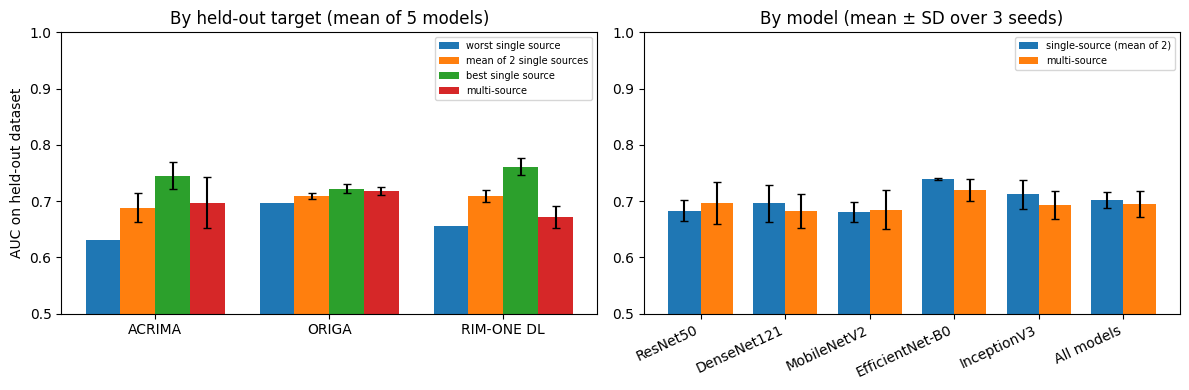

In [72]:
# ===== MS3: compare with the previous single-source results  =====
# Pre-specified (fix before looking): primary outcome = AUC on the held-out dataset, multi-source
# vs the mean of the two single-source models for the same target; all models averaged per seed;
# 95% CI with t (2 d.f.). "Improvement supported" only if the CI excludes 0 AND the gain is >= 0.02.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
ARMS = [
    a for a in ['ms', 'msm'] if all(os.path.isfile(f'{MS_OUT}/ms_results_{a}_seed{s}.csv') for s in SEEDS)
]
LABEL = {
    'ACRIMA': 'ACRIMA',
    'ORIGA': 'ORIGA',
    'RIM-ONE_DL': 'RIM-ONE DL',
    'G1020': 'G1020',
    'ALL': 'All models',
    'resnet50': 'ResNet50',
    'densenet121': 'DenseNet121',
    'mobilenet_v2': 'MobileNetV2',
    'efficientnet_b0': 'EfficientNet-B0',
    'inception_v3': 'InceptionV3',
    'ms': 'Multi-source (all data)',
    'msm': 'Multi-source (size-matched)',
}
def check(c, msg):
    if not c:
        raise ValueError('MS CHECK FAILED: ' + msg)
def pm(m, s, d=3):
    return f'{m:.{d}f} ± {s:.{d}f}'
def save(d, name):
    d.to_csv(f'{MS_OUT}/{name}', index=False, encoding='utf-8-sig')
    print('saved', name, d.shape)
def agg(d, keys, cols):  # mean and sample SD (ddof=1) ACROSS SEEDS
    g = d.groupby(keys, sort=False)
    o = g[cols].mean().add_suffix('_mean').join(g[cols].std(ddof=1).add_suffix('_sd'))
    o['n_seeds'] = g['seed'].nunique()
    check((o.n_seeds == len(SEEDS)).all(), f'{keys}: a group lacks a seed')
    return o.reset_index()
def ci95(x):
    x = np.asarray(x, float)
    h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return x.mean() - h, x.mean() + h
check(len(ARMS) > 0, 'no complete arm found: run MS1 and MS2 for all three seeds')
# ---- old single-source results: read only, never modified -------------------------------
old = pd.concat([pd.read_csv(f'{OUT}/results_seed{s}.csv') for s in SEEDS], ignore_index=True)
old = old[old.source.isin(SOURCES)]
oldp = old[old.target.isin(SOURCES)]
cross = oldp[oldp.source != oldp.target]
base = (
    cross.groupby(['seed', 'model', 'target'])
    .agg(
        single_mean=('auc', 'mean'),
        single_best=('auc', 'max'),
        single_worst=('auc', 'min'),
        sens_single=('sens', 'mean'),
        spec_single=('spec', 'mean'),
        n_src=('source', 'nunique'),
    )
    .reset_index()
    .rename(columns={'target': 'heldout'})
)
check((base.n_src == 2).all(), 'old results: need exactly two single-source models per target')
base['bal_single'] = (base.sens_single + base.spec_single) / 2
oldD = (
    oldp.assign(g=np.where(oldp.source == oldp.target, 'in', 'cross'))
    .groupby(['model', 'seed', 'g'])
    .auc.mean()
    .unstack()
)
oldD['old_drop'] = oldD['in'] - oldD['cross']
oldD = oldD.reset_index()  # same definition as the paper
print(
    'OLD cross-source AUC, all models (paper: 0.701):',
    round(oldD.groupby('seed')['cross'].mean().mean(), 3),
)
print(
    'OLD AUC drop, all models        (paper: 0.219):', round(oldD.groupby('seed').old_drop.mean().mean(), 3)
)
old_ext = (
old[old.target == EXTERNAL].groupby(['model', 'seed']).auc.mean().rename('single_g1020').reset_index()
)
H, GAIN, TAB_D, TAB_G, TAB_X, TAB_T = [], [], [], [], [], []
for arm in ARMS:
    res = pd.concat(
        [pd.read_csv(f'{MS_OUT}/ms_results_{arm}_seed{s}.csv') for s in SEEDS], ignore_index=True
    )
    # ---- (a) held-out target: paired with the single-source cells on the SAME images -----
    h = res[res.role == 'held-out'].merge(base, on=['seed', 'model', 'heldout'], validate='one_to_one')
    h['bal'] = (h.sens + h.spec) / 2
    h['gain_vs_mean'] = h.auc - h.single_mean  # PRIMARY
    h['gain_vs_best'] = h.auc - h.single_best  # optimistic: best source picked using target labels
    h['gain_vs_worst'] = h.auc - h.single_worst
    h['d_sens'] = h.sens - h.sens_single
    h['d_spec'] = h.spec - h.spec_single
    h['d_bal'] = h.bal - h.bal_single
    check(len(h) == 45, 'held-out rows should be 3 seeds x 5 models x 3 targets = 45')
    h['arm'] = arm
    H.append(h)
GC = [
    'auc',
    'single_mean',
    'single_best',
    'single_worst',
    'gain_vs_mean',
    'gain_vs_best',
    'gain_vs_worst',
    'sens',
    'spec',
    'bal',
    'sens_single',
    'spec_single',
    'bal_single',
    'd_sens',
    'd_spec',
    'd_bal',
]
Hh = pd.concat(H, ignore_index=True)
save(Hh, 'ms_heldout_pair_seed.csv')  # audit trail
# ---- Table A: per model and ALL (seed level first, then mean ± SD over seeds) -------------
ms_ = Hh.groupby(['arm', 'model', 'seed'], as_index=False, sort=False)[GC].mean()
al_ = ms_.groupby(['arm', 'seed'], as_index=False, sort=False)[GC].mean()
al_.insert(1, 'model', 'ALL')
TA = pd.concat([agg(ms_, ['arm', 'model'], GC), agg(al_, ['arm', 'model'], GC)], ignore_index=True)
save(TA, 'ms_vs_single_model_mean_sd.csv')
for arm in ARMS:
    t = TA[TA.arm == arm]
    show = pd.DataFrame({'Model': t.model.map(LABEL)})
    for c, nm in [
        ('single_mean', 'Single-source (mean of 2)'),
        ('single_best', 'Best single'),
        ('auc', 'Multi-source'),
        ('gain_vs_mean', 'Gain vs mean'),
    ]:
        show[nm] = [pm(a, b) for a, b in zip(t[f'{c}_mean'], t[f'{c}_sd'])]
    print(f'\n[{LABEL[arm]}] AUC on the held-out dataset (mean ± SD over 3 seeds)')
    print(show.to_string(index=False))
    a = al_[al_.arm == arm]
    for c, nm in [
        ('gain_vs_mean', 'PRIMARY gain vs mean of single-source'),
        ('gain_vs_best', 'gain vs best single-source'),
        ('d_spec', 'change in specificity'),
        ('d_sens', 'change in sensitivity'),
        ('d_bal', 'change in balanced acc.'),
    ]:
        lo, hi = ci95(a[c])
        print(f'  {nm:42s} {a[c].mean():+.3f}  (95% CI {lo:+.3f} to {hi:+.3f})')
    lo, hi = ci95(a.gain_vs_mean)
    print(
        f'  RULE: CI excludes 0: {lo > 0 or hi < 0} | gain >= 0.02: {a.gain_vs_mean.mean() >= 0.02} '
        f'-> improvement supported: {(lo > 0) and a.gain_vs_mean.mean() >= 0.02}'
    )
# ---- Table B: per held-out target (which dataset benefits?) -------------------------------
tg = Hh.groupby(['arm', 'heldout', 'seed'], as_index=False, sort=False)[GC].mean()
TB = agg(tg, ['arm', 'heldout'], GC)
save(TB, 'ms_vs_single_by_target_mean_sd.csv')
for arm in ARMS:
    t = TB[TB.arm == arm]
    show = pd.DataFrame({'Held-out target': t.heldout.map(LABEL)})
    for c, nm in [
        ('single_mean', 'Single (mean of 2)'),
        ('single_best', 'Best single'),
        ('auc', 'Multi-source'),
        ('gain_vs_mean', 'Gain'),
    ]:
        show[nm] = [pm(a, b) for a, b in zip(t[f'{c}_mean'], t[f'{c}_sd'])]
    print(f'\n[{LABEL[arm]}] by held-out target (mean over 5 models, ± SD over seeds)')
    print(show.to_string(index=False))
# ---- Table C: AUC drop, old vs new (new defined with the same logic) -----------------------
D = []
for arm in ARMS:
    res = pd.concat(
        [pd.read_csv(f'{MS_OUT}/ms_results_{arm}_seed{s}.csv') for s in SEEDS], ignore_index=True
    )
    ind = res[res.role == 'source-test'].groupby(['model', 'seed']).auc.mean().rename('ms_in_domain')
    out = res[res.role == 'held-out'].groupby(['model', 'seed']).auc.mean().rename('ms_heldout')
    d = pd.concat([ind, out], axis=1).reset_index()
    d['ms_drop'] = d.ms_in_domain - d.ms_heldout
    d['arm'] = arm
    D.append(
        d.merge(
            oldD.rename(columns={'in': 'old_in_domain', 'cross': 'old_cross_source'}), on=['model', 'seed']
        )
    )
D = pd.concat(D, ignore_index=True)
D['drop_change'] = D.ms_drop - D.old_drop
save(D, 'ms_auc_drop_per_seed.csv')
dm = D.groupby(['arm', 'seed'], as_index=False).mean(numeric_only=True)
for arm in ARMS:
    a = dm[dm.arm == arm]
    print(f'\n[{LABEL[arm]}] AUC drop, all models, mean over seeds')
    print(
        f'  OLD (single-source): in-domain {a.old_in_domain.mean():.3f} | '
        f'cross-source {a.old_cross_source.mean():.3f} | drop {a.old_drop.mean():.3f}'
    )
    print(
        f'  NEW (multi-source) : in-domain {a.ms_in_domain.mean():.3f} | '
        f'held-out {a.ms_heldout.mean():.3f} | drop {a.ms_drop.mean():.3f}'
    )
    lo, hi = ci95(a.drop_change)
    print(f'  change of the drop: {a.drop_change.mean():+.3f} (95% CI {lo:+.3f} to {hi:+.3f})')
save(
    agg(
        D.groupby(['arm', 'model', 'seed'], as_index=False).mean(numeric_only=True),
        ['arm', 'model'],
        [
            'old_in_domain',
            'old_cross_source',
            'old_drop',
            'ms_in_domain',
            'ms_heldout',
            'ms_drop',
            'drop_change',
        ],
  ),
    'ms_auc_drop_mean_sd.csv',
)
# ---- Table D: G1020 (external, kept apart; no pooling with the held-out results) ----------
X = []
for arm in ARMS:
    res = pd.concat(
        [pd.read_csv(f'{MS_OUT}/ms_results_{arm}_seed{s}.csv') for s in SEEDS], ignore_index=True
    )
    x = (
        res[res.role == 'external']
        .groupby(['model', 'seed'], as_index=False)
        .auc.mean()
        .rename(columns={'auc': 'ms_g1020'})
    )
    x = x.merge(old_ext, on=['model', 'seed'], validate='one_to_one')
    x['gain'] = x.ms_g1020 - x.single_g1020
    x['arm'] = arm
    X.append(x)
X = pd.concat(X, ignore_index=True)
save(agg(X, ['arm', 'model'], ['single_g1020', 'ms_g1020', 'gain']), 'ms_external_G1020_mean_sd.csv')
for arm in ARMS:
    a = X[X.arm == arm].groupby('seed')[['single_g1020', 'ms_g1020', 'gain']].mean()
    print(
        f'\n[{LABEL[arm]}] G1020 mean AUC over models: single-source {a.single_g1020.mean():.3f} '
        f'-> multi-source {a.ms_g1020.mean():.3f}'
    )
# ---- Figure -----------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(SOURCES))
w = 0.2
tb = TB[TB.arm == ARMS[0]].set_index('heldout').loc[SOURCES]
ax[0].bar(x - 1.5 * w, tb.single_worst_mean, w, label='worst single source')
ax[0].bar(
    x - 0.5 * w, tb.single_mean_mean, w, yerr=tb.single_mean_sd, capsize=3, label='mean of 2 single sources'
)
ax[0].bar(
    x + 0.5 * w, tb.single_best_mean, w, yerr=tb.single_best_sd, capsize=3, label='best single source'
)
ax[0].bar(x + 1.5 * w, tb.auc_mean, w, yerr=tb.auc_sd, capsize=3, label='multi-source')
ax[0].set_xticks(x)
ax[0].set_xticklabels([LABEL[s] for s in SOURCES])
ax[0].set_ylim(0.5, 1.0)
ax[0].set_ylabel('AUC on held-out dataset')
ax[0].legend(fontsize=7)
ax[0].set_title('By held-out target (mean of 5 models)')
tm = TA[(TA.arm == ARMS[0])]
xm = np.arange(len(tm))
ax[1].bar(
    xm - 0.19,
    tm.single_mean_mean,
    0.38,
    yerr=tm.single_mean_sd,
    capsize=3,
    label='single-source (mean of 2)',
)
ax[1].bar(xm + 0.19, tm.auc_mean, 0.38, yerr=tm.auc_sd, capsize=3, label='multi-source')
ax[1].set_xticks(xm)
ax[1].set_xticklabels(tm.model.map(LABEL), rotation=25, ha='right')
ax[1].set_ylim(0.5, 1.0)
ax[1].set_title('By model (mean ± SD over 3 seeds)')
ax[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig(f'{MS_OUT}/ms_vs_single_auc.png', dpi=200)
plt.show()

In [73]:
# ===== MS4 : threshold recalibration on the multi-source scores =====
# Same rule as cell R3 (10% of the held-out target, Youden's J, 200 splits, before/after on the SAME 90%).
# Possible without retraining because MS1 saved the scores. Writes only to results/multisource/.
from sklearn.metrics import roc_curve
CAL_FRAC, N_REP = 0.10, 200
def youden_thr(y, p):
    fpr, tpr, th = roc_curve(y, p)
    k = 1 + int(np.argmax((tpr - fpr)[1:]))
    return float(th[k])
def rates(y, p, thr):
    pr = p >= thr
    pos = y == 1
    neg = y == 0
    return (pr & pos).sum() / pos.sum(), (~pr & neg).sum() / neg.sum()
RC = []
for arm in ARMS:
    for s in SEEDS:
        for held in SOURCES:
            for name in MODELS:
                g = pd.read_csv(f'{MS_PRED}/seed{s}_{arm}_{name}_{held}.csv')
                g = g[g.role == 'held-out']
                y = g.label.values.astype(int)
                p = g.score.values
                thr0 = g.thr.iloc[0]
                idx = np.arange(len(y))
                R = []
                for r in range(N_REP):
                    ci, ei = train_test_split(
                        idx, train_size=CAL_FRAC, stratify=y, random_state=1000 * s + r
                    )
                    b = rates(y[ei], p[ei], thr0)
                    a = rates(y[ei], p[ei], youden_thr(y[ci], p[ci]))
                    R.append([*b, *a])
                R = np.array(R).mean(0)
                RC.append(
                    dict(
                        arm=arm,
                        seed=s,
                        model=name,
                        heldout=held,
                        sens_before=R[0],
                        spec_before=R[1],
                        sens_after=R[2],
                        spec_after=R[3],
                    )
                )
RC = pd.DataFrame(RC)
RC['bal_before'] = (RC.sens_before + RC.spec_before) / 2
RC['bal_after'] = (RC.sens_after + RC.spec_after) / 2
save(RC, 'ms_recal_pair_seed.csv')
VR = ['sens_before', 'sens_after', 'spec_before', 'spec_after', 'bal_before', 'bal_after']
sm_ = RC.groupby(['arm', 'model', 'seed'], as_index=False)[VR].mean()
al2 = sm_.groupby(['arm', 'seed'], as_index=False)[VR].mean()
al2.insert(1, 'model', 'ALL')
T4 = pd.concat([agg(sm_, ['arm', 'model'], VR), agg(al2, ['arm', 'model'], VR)], ignore_index=True)
save(T4, 'ms_recal_model_mean_sd.csv')
for arm in ARMS:
    t = T4[(T4.arm == arm) & (T4.model == 'ALL')].iloc[0]
    print(
        f'[{LABEL[arm]}] held-out, all models: specificity {t.spec_before_mean:.3f} -> {t.spec_after_mean:.3f} | '
        f'sensitivity {t.sens_before_mean:.3f} -> {t.sens_after_mean:.3f} | '
        f'balanced {t.bal_before_mean:.3f} -> {t.bal_after_mean:.3f}'
    )
f_old = f'{OUT}/recal_primary_model_mean_sd.csv'
if os.path.isfile(f_old):
    o = pd.read_csv(f_old)
    o = o[o.model == 'ALL'].iloc[0]
    print(
        f'(single-source reference from R3, 6 pairs: '
        f'specificity {o.spec_before_mean:.3f} -> {o.spec_after_mean:.3f}, '
        f'balanced {o.bal_before_mean:.3f} -> {o.bal_after_mean:.3f})'
    )


saved ms_recal_pair_seed.csv (90, 10)
saved ms_recal_model_mean_sd.csv (12, 15)
[Multi-source (all data)] held-out, all models: specificity 0.467 -> 0.654 | sensitivity 0.757 -> 0.615 | balanced 0.612 -> 0.635
[Multi-source (size-matched)] held-out, all models: specificity 0.474 -> 0.659 | sensitivity 0.784 -> 0.634 | balanced 0.629 -> 0.647
(single-source reference from R3, 6 pairs: specificity 0.506 -> 0.670, balanced 0.616 -> 0.639)
